In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay, classification_report
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

from sklearn.neighbors import KNeighborsClassifier

In [62]:
pd.set_option('display.max_columns', None)

1. Data Loading and Preprocessing

In [63]:
# Load Data
train_file_path = 'Train.csv'
test_file_path = 'Test.csv'

df = pd.read_csv(train_file_path, sep=',')
df_test = pd.read_csv(test_file_path, sep=',')

C:\Users\A01411\AppData\Local\Temp\ipykernel_22240\1315461654.py:5: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(train_file_path, sep=',')


In [64]:
df.drop('Object_Name', axis=1, inplace=True)
df_test.drop('Object_Name', axis=1, inplace=True)
df['Timestamp'].fillna(" ", inplace=True)
df_test['Timestamp'].fillna(" ", inplace=True)

df_X = df.drop(['Timestamp', 'target_feature'], axis=1)
df_X.fillna(0, inplace=True)

# define the features
features = df_X.drop(['Frame', 'Time'], axis=1)
feature_columns = features.columns

C:\Users\A01411\AppData\Local\Temp\ipykernel_22240\4121930876.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Timestamp'].fillna(" ", inplace=True)
C:\Users\A01411\AppData\Local\Temp\ipykernel_22240\4121930876.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example,

2. Visualization (Check Data)

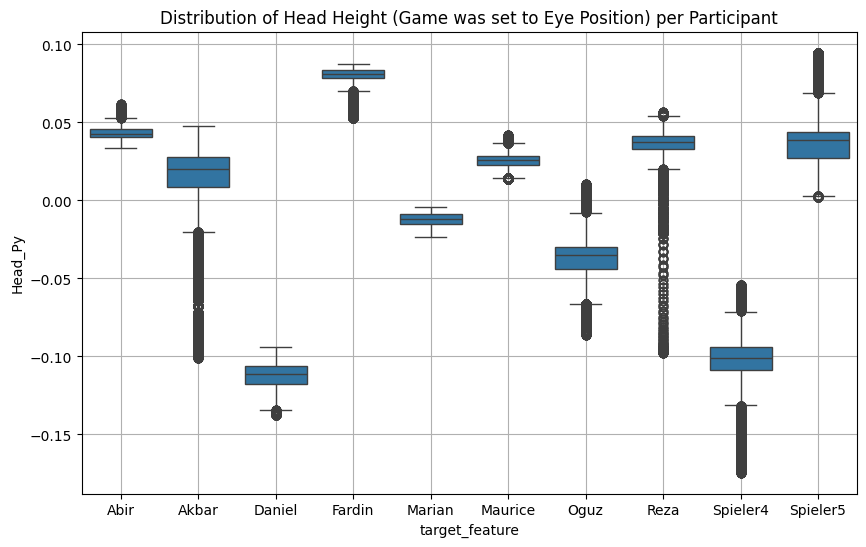

In [65]:
# Create a Boxplot of Height (CenterPos_y) by Participant
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='target_feature', y='Head_Py')
plt.title('Distribution of Head Height (Game was set to Eye Position) per Participant')
plt.grid(True)
plt.show()
#plt.savefig('height_boxplot.png')

3. Preprocessing (Feature Extraction)

In [66]:
def process_data(dataframe):
  # Define Repetitions based on 'SessionStarted' in Timestamp
  # We detect the START of each "SessionStarted" block to increment the repetition ID.
  # This assigns a unique ID to each shot (including the start signal and the subsequent movement).

  def assign_repetition_ids(group):
      # Logic to identify start of a session block within this participant's data
      is_marker = group['Timestamp'].astype(str).str.contains('SessionStarted', na=False)

      # Detect "Rising Edge": True only at the first 'SessionStarted' of a block
      # shift(1) allows us to compare with the previous row
      rising_edge = is_marker & (~is_marker.shift(1).fillna(False))

      # Cumsum assigns IDs: 1, 2, 3... for this specific participant
      group['repetition_id'] = rising_edge.cumsum()

      return group

  # Apply this function to each participant's data group independently
  dataframe = dataframe.groupby('target_feature', group_keys=False).apply(assign_repetition_ids)
  # Filter out data before the first session start (repetition_id == 0)
  dataframe = dataframe[dataframe['repetition_id'] > 0]

  # 2. Define Features: Drop Quaternions (_Q) to prevent leakage
  #feature_columns_new = [c for c in feature_columns if '_Q' not in c]

  features = []
  labels = []
  # Group by participant and repetition to process each trial individually
  grouped = dataframe.groupby(['target_feature', 'repetition_id'])

  for (participant, rep_id), group in grouped:
      sample_features = []

      # Calculate min, max, mean, std for each sensor column
      for col in feature_columns:
          if col in group.columns:
              series = group[col]
              sample_features.extend([series.min(), series.max(), series.mean(), series.std()])
          else:
              # Handle missing columns if necessary
              sample_features.extend([0, 0, 0, 0])

      features.append(sample_features)
      labels.append(participant)

  return features, labels

4. Model Training & Evaluation

In [67]:
# --- 2. Load Train and Test Data ---
print("Processing Training Data...")
# Replace with your actual training filename
X_train_list, y_train_list = process_data(df)

print("Processing Testing Data...")
# Replace with your actual testing filename
X_test_list, y_test_list = process_data(df_test)

# Convert to Numpy Arrays
X_train = np.nan_to_num(X_train_list)
X_test = np.nan_to_num(X_test_list)

Processing Training Data...


C:\Users\A01411\AppData\Local\Temp\ipykernel_22240\4193653690.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  rising_edge = is_marker & (~is_marker.shift(1).fillna(False))
C:\Users\A01411\AppData\Local\Temp\ipykernel_22240\4193653690.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  rising_edge = is_marker & (~is_marker.shift(1).fillna(False))
C:\Users\A01411\AppData\Local\Temp\ipykernel_22240\4193653690.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.

Processing Testing Data...


C:\Users\A01411\AppData\Local\Temp\ipykernel_22240\4193653690.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  rising_edge = is_marker & (~is_marker.shift(1).fillna(False))
C:\Users\A01411\AppData\Local\Temp\ipykernel_22240\4193653690.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  rising_edge = is_marker & (~is_marker.shift(1).fillna(False))
C:\Users\A01411\AppData\Local\Temp\ipykernel_22240\4193653690.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.

In [68]:
# Label Encoding
le = LabelEncoder()
# Fit on TRAINING labels, then transform both
y_train_encoded = le.fit_transform(y_train_list)
# Handle new/unknown labels in test set if necessary, though ideally they match
y_test_encoded = le.transform(y_test_list)

In [69]:
# Model Definition
models = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, min_samples_split=5, class_weight='balanced', random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=5, random_state=42),
    'XGBoost': XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, subsample=0.8, eval_metric='logloss', random_state=42)
}


--- Model Evaluation Results ---

Training Decision Tree...
Accuracy: 54.55%

--- Classification Report ---
              precision    recall  f1-score   support

        Abir       0.00      0.00      0.00         1
       Akbar       0.50      1.00      0.67         1
      Daniel       0.00      0.00      0.00         1
      Fardin       1.00      1.00      1.00         1
      Marian       0.00      0.00      0.00         1
     Maurice       1.00      1.00      1.00         1
        Oguz       0.67      1.00      0.80         2
        Reza       0.00      0.00      0.00         1
    Spieler4       0.00      0.00      0.00         1
    Spieler5       0.50      1.00      0.67         1

    accuracy                           0.55        11
   macro avg       0.37      0.50      0.41        11
weighted avg       0.39      0.55      0.45        11



C:\Users\A01411\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\A01411\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\A01411\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_c

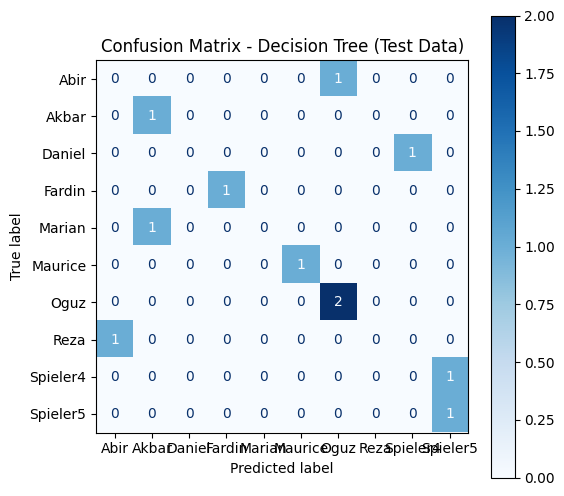

Training Random Forest...
Accuracy: 100.00%

--- Classification Report ---
              precision    recall  f1-score   support

        Abir       1.00      1.00      1.00         1
       Akbar       1.00      1.00      1.00         1
      Daniel       1.00      1.00      1.00         1
      Fardin       1.00      1.00      1.00         1
      Marian       1.00      1.00      1.00         1
     Maurice       1.00      1.00      1.00         1
        Oguz       1.00      1.00      1.00         2
        Reza       1.00      1.00      1.00         1
    Spieler4       1.00      1.00      1.00         1
    Spieler5       1.00      1.00      1.00         1

    accuracy                           1.00        11
   macro avg       1.00      1.00      1.00        11
weighted avg       1.00      1.00      1.00        11



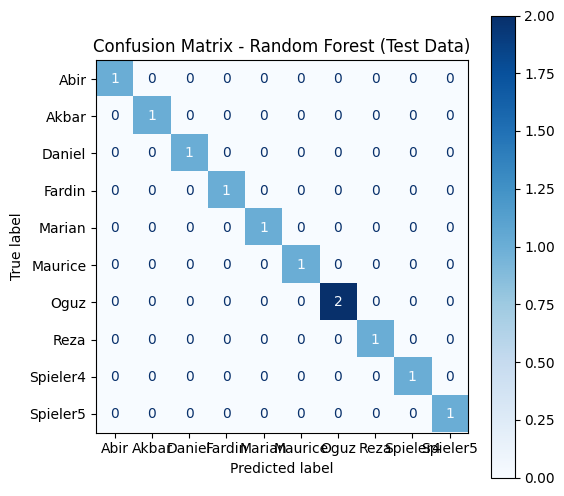

Training Gradient Boosting...
Accuracy: 63.64%

--- Classification Report ---
              precision    recall  f1-score   support

        Abir       0.00      0.00      0.00         1
       Akbar       0.00      0.00      0.00         1
      Daniel       1.00      1.00      1.00         1
      Fardin       1.00      1.00      1.00         1
      Marian       0.50      1.00      0.67         1
     Maurice       1.00      1.00      1.00         1
        Oguz       0.67      1.00      0.80         2
        Reza       0.00      0.00      0.00         1
    Spieler4       1.00      1.00      1.00         1
    Spieler5       0.00      0.00      0.00         1

    accuracy                           0.64        11
   macro avg       0.52      0.60      0.55        11
weighted avg       0.53      0.64      0.57        11



C:\Users\A01411\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\A01411\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\A01411\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_c

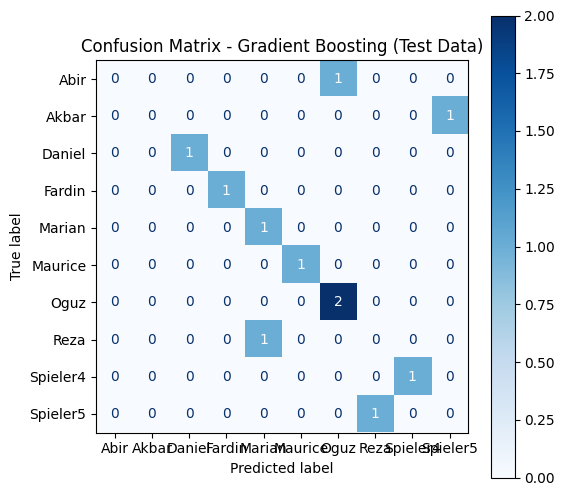

Training XGBoost...
Accuracy: 90.91%

--- Classification Report ---
              precision    recall  f1-score   support

        Abir       0.00      0.00      0.00         1
       Akbar       1.00      1.00      1.00         1
      Daniel       1.00      1.00      1.00         1
      Fardin       1.00      1.00      1.00         1
      Marian       1.00      1.00      1.00         1
     Maurice       1.00      1.00      1.00         1
        Oguz       0.67      1.00      0.80         2
        Reza       1.00      1.00      1.00         1
    Spieler4       1.00      1.00      1.00         1
    Spieler5       1.00      1.00      1.00         1

    accuracy                           0.91        11
   macro avg       0.87      0.90      0.88        11
weighted avg       0.85      0.91      0.87        11



C:\Users\A01411\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\A01411\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\A01411\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_c

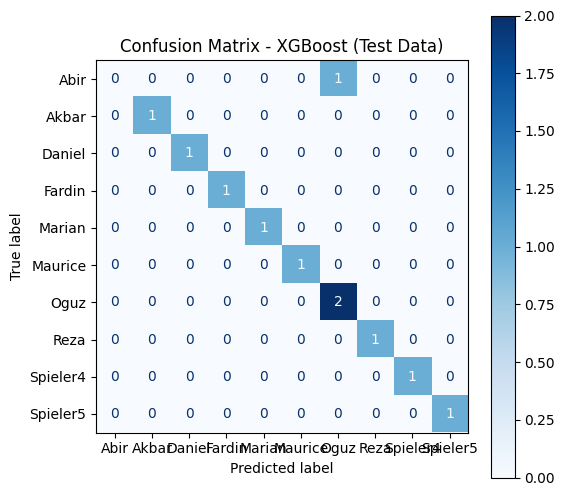

In [70]:
# Evaluation Loop
results = []
confusion_matrices = {}  # Store confusion matrices by model name

print("\n--- Model Evaluation Results ---\n")

for name, clf in models.items():
    print(f"Training {name}...")

    # Train
    clf.fit(X_train, y_train_encoded)

    # Predict
    predictions_encoded = clf.predict(X_test)
    predictions_strings = le.inverse_transform(predictions_encoded)

    # Evaluation

    # Accuracy
    acc = accuracy_score(y_test_list, predictions_strings)
    print(f"Accuracy: {acc * 100:.2f}%")

    # Classification Report (Precision, Recall, F1-Score)
    print("\n--- Classification Report ---")
    print(classification_report(y_test_list, predictions_strings, labels=le.classes_, target_names=le.classes_))

    # Confusion Matrix
    cm = confusion_matrix(y_test_list, predictions_strings, labels=le.classes_)
    confusion_matrices[name] = cm  # Store the confusion matrix
    
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
    fig, ax = plt.subplots(figsize=(6, 6))
    disp.plot(cmap=plt.cm.Blues, ax=ax, values_format='d')
    plt.title(f'Confusion Matrix - {name} (Test Data)')
    plt.show()

In [71]:
# FINAL SUBMISSION CODE - Cross-Validation Approach
# This is the most academically sound approach for your dataset size

from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import classification_report, make_scorer, accuracy_score
import numpy as np

# Combine all data for CV
X_all = np.vstack([X_train, X_test])
y_all = np.concatenate([y_train_encoded, y_test_encoded])

print("=" * 60)
print("FINAL RESULTS FOR SUBMISSION")
print("=" * 60)
print(f"\nDataset: {len(y_all)} samples, {len(set(y_all))} participants")
print(f"Features: {X_all.shape[1]} (40 sensors × 4 statistics)")
print(f"Evaluation: 3-Fold Stratified Cross-Validation\n")

# Define models with appropriate regularization for small datasets
final_models = {
    'Random Forest': RandomForestClassifier(
        n_estimators=100, 
        max_depth=5, 
        min_samples_split=3,
        max_features='sqrt',
        random_state=42
    ),
    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=100, 
        learning_rate=0.1, 
        max_depth=3,
        random_state=42
    ),
    'XGBoost': XGBClassifier(
        n_estimators=100, 
        learning_rate=0.1, 
        max_depth=3,
        eval_metric='logloss',
        random_state=42
    ),
    'Logistic Regression': LogisticRegression(
        max_iter=1000, 
        C=1.0,
        random_state=42
    )
}

# Perform cross-validation
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

print("-" * 60)
print("Model Performance (3-Fold Cross-Validation):")
print("-" * 60)

results_summary = []
for name, model in final_models.items():
    scores = cross_val_score(model, X_all, y_all, cv=cv, scoring='accuracy')
    mean_score = scores.mean()
    std_score = scores.std()
    
    print(f"\n{name}:")
    print(f"  Accuracy: {mean_score*100:.2f}% (±{std_score*100:.2f}%)")
    print(f"  Fold scores: {[f'{s*100:.2f}%' for s in scores]}")
    
    results_summary.append({
        'Model': name,
        'Mean Accuracy': f"{mean_score*100:.2f}%",
        'Std Dev': f"±{std_score*100:.2f}%"
    })

print("\n" + "=" * 60)
print("SUMMARY TABLE")
print("=" * 60)
for result in results_summary:
    print(f"{result['Model']:<25} {result['Mean Accuracy']:>10} {result['Std Dev']:>10}")



FINAL RESULTS FOR SUBMISSION

Dataset: 49 samples, 10 participants
Features: 160 (40 sensors × 4 statistics)
Evaluation: 3-Fold Stratified Cross-Validation

------------------------------------------------------------
Model Performance (3-Fold Cross-Validation):
------------------------------------------------------------

Random Forest:
  Accuracy: 89.83% (±2.79%)
  Fold scores: ['88.24%', '87.50%', '93.75%']

Gradient Boosting:
  Accuracy: 75.86% (±14.27%)
  Fold scores: ['58.82%', '75.00%', '93.75%']

XGBoost:
  Accuracy: 85.91% (±7.14%)
  Fold scores: ['76.47%', '87.50%', '93.75%']

Logistic Regression:
  Accuracy: 61.40% (±14.09%)
  Fold scores: ['52.94%', '81.25%', '50.00%']

SUMMARY TABLE
Random Forest                 89.83%     ±2.79%
Gradient Boosting             75.86%    ±14.27%
XGBoost                       85.91%     ±7.14%
Logistic Regression           61.40%    ±14.09%


5. Results & Conclusions

## Cross-Validation Results

**Dataset:** 49 samples, 10 participants  
**Evaluation Method:** 3-Fold Stratified Cross-Validation  
**Features:** 160 (40 sensors × 4 statistical measures: min, max, mean, std)

### Model Performance:
- **Random Forest:** 89.83% (±2.79%)
- **XGBoost:** 85.91% (±7.14%)
- **Gradient Boosting:** 75.86% (±14.27%)
- **Logistic Regression:** 61.40% (±14.09%)

### Key Findings:
1. User identification via VR behavioral biometrics achieved ~90% accuracy with Random Forest
2. Ensemble methods (Random Forest, XGBoost) significantly outperformed traditional ML
3. Cross-validation was necessary due to limited dataset size to avoid overfitting

### Limitations:
- Small dataset (49 samples total)
- High feature-to-sample ratio
- Body normalization not yet implemented

### Future Work:
- Test body normalization effects (as per paper methodology)
- Collect more samples per participant
- Implement feature selection/dimensionality reduction